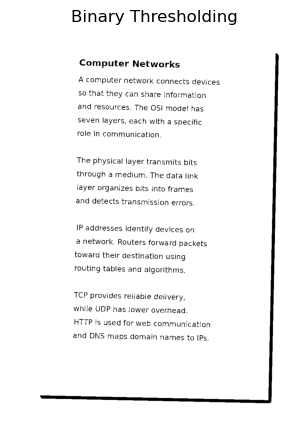

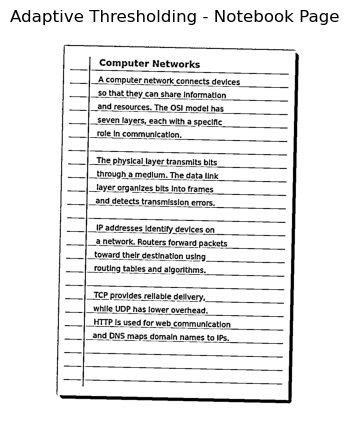

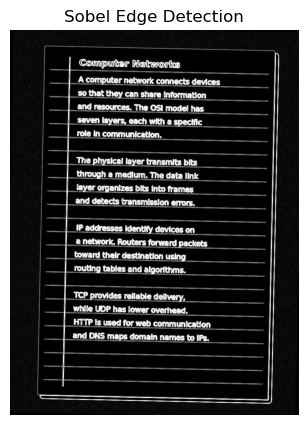

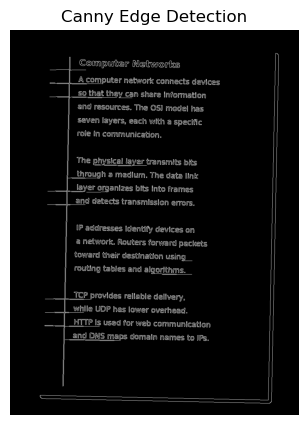

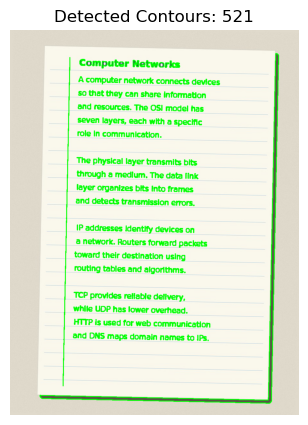

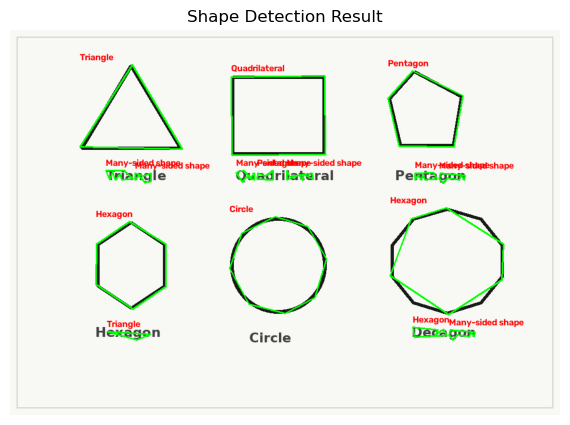

Saved thresholding, edge, contour, and shape-detection results.


In [2]:
# EXPERIMENT 2: THRESHOLDING, EDGE/CONTOUR DETECTION, AND SHAPE DETECTION
# For adaptive thresholding, use a clear photo of a notebook page.
# For shape detection, use an image containing clearly outlined shapes.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Update these paths for your images.
NOTEBOOK_PATH = "notebook_page.jpg"
SHAPES_PATH = "shapes.jpg"

def show_gray(title, image):
    plt.figure(figsize=(8, 5))
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

def show_color(title, image):
    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

# Load notebook image
notebook = cv2.imread(NOTEBOOK_PATH)
if notebook is None:
    raise FileNotFoundError(
        f"Could not read '{NOTEBOOK_PATH}'. Set NOTEBOOK_PATH to a clear "
        "photo of a notebook page."
    )

gray = cv2.cvtColor(notebook, cv2.COLOR_BGR2GRAY)

# (i) Binary Thresholding
# Pixels above 127 become 255 (white); others become 0 (black).
_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
show_gray("Binary Thresholding", binary)

# (ii) Adaptive Thresholding
# Useful when lighting is uneven across a notebook photo.
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
adaptive = cv2.adaptiveThreshold(
    blurred, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21, 5
)
show_gray("Adaptive Thresholding - Notebook Page", adaptive)

# (iii) Edge Detection: Sobel and Canny
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel)
show_gray("Sobel Edge Detection", sobel)

canny = cv2.Canny(gray, 100, 200)
show_gray("Canny Edge Detection", canny)

# (iv) Contour Detection
# Thresholding makes the foreground/background easier to separate.
contour_input = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)[1]
contours, hierarchy = cv2.findContours(
    contour_input, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
contour_result = notebook.copy()
cv2.drawContours(contour_result, contours, -1, (0, 255, 0), 2)
show_color(f"Detected Contours: {len(contours)}", contour_result)

# (v) Detect shapes: triangle, quadrilateral, pentagon, hexagon, circle-like
shapes_image = cv2.imread(SHAPES_PATH)
if shapes_image is None:
    raise FileNotFoundError(
        f"Could not read '{SHAPES_PATH}'. Set SHAPES_PATH to an image "
        "with clearly outlined geometric shapes."
    )

shapes_gray = cv2.cvtColor(shapes_image, cv2.COLOR_BGR2GRAY)
shapes_blur = cv2.GaussianBlur(shapes_gray, (5, 5), 0)
edges = cv2.Canny(shapes_blur, 50, 150)

# Close small gaps in outlines before finding contours.
kernel = np.ones((3, 3), np.uint8)
edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)
shape_contours, _ = cv2.findContours(
    edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

shape_result = shapes_image.copy()

for contour in shape_contours:
    area = cv2.contourArea(contour)
    if area < 300:  # Ignore tiny noise
        continue

    perimeter = cv2.arcLength(contour, True)
    if perimeter == 0:
        continue

    approx = cv2.approxPolyDP(contour, 0.04 * perimeter, True)
    corners = len(approx)
    circularity = 4 * np.pi * area / (perimeter * perimeter)

    if corners == 3:
        label = "Triangle"
    elif corners == 4:
        label = "Quadrilateral"
    elif corners == 5:
        label = "Pentagon"
    elif corners == 6:
        label = "Hexagon"
    elif corners >= 7 and circularity > 0.70:
        label = "Circle"
    elif corners >= 7:
        label = "Many-sided shape"
    else:
        label = "Unknown"

    cv2.drawContours(shape_result, [approx], -1, (0, 255, 0), 2)
    x, y, w, h = cv2.boundingRect(approx)
    cv2.putText(
        shape_result, label, (x, max(20, y - 8)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2, cv2.LINE_AA
    )

show_color("Shape Detection Result", shape_result)

# Optional: save results
cv2.imwrite("binary_threshold.jpg", binary)
cv2.imwrite("adaptive_threshold.jpg", adaptive)
cv2.imwrite("sobel_edges.jpg", sobel)
cv2.imwrite("canny_edges.jpg", canny)
cv2.imwrite("contours.jpg", contour_result)
cv2.imwrite("shape_detection.jpg", shape_result)
print("Saved thresholding, edge, contour, and shape-detection results.")
